In [1]:
# Network Intrusion Detection Using Machine Learning

print("Network Intrusion Detection Project")
print("Environment setup successful!")

Network Intrusion Detection Project
Environment setup successful!


In [2]:
!pip -q install pandas numpy scikit-learn matplotlib seaborn joblib

In [3]:
import pandas as pd
import numpy as np

# Download the NSL-KDD training dataset
url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"

columns = [
    "duration", "protocol_type", "service", "flag", "src_bytes",
    "dst_bytes", "land", "wrong_fragment", "urgent", "hot",
    "num_failed_logins", "logged_in", "num_compromised",
    "root_shell", "su_attempted", "num_root", "num_file_creations",
    "num_shells", "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count", "srv_count",
    "serror_rate", "srv_serror_rate", "rerror_rate",
    "srv_rerror_rate", "same_srv_rate", "diff_srv_rate",
    "srv_diff_host_rate", "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate", "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "label", "difficulty"
]

df = pd.read_csv(url, names=columns)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
df.head()

Dataset loaded successfully!
Dataset shape: (125973, 43)


,duration,protocol_type,service,flag,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,...,dst_host_same_srv_rate,dst_host_diff_srv_rate,dst_host_same_src_port_rate,dst_host_srv_diff_host_rate,dst_host_serror_rate,dst_host_srv_serror_rate,dst_host_rerror_rate,dst_host_srv_rerror_rate,label,difficulty
0,0,tcp,ftp_data,SF,491,0,0,0,0,0,...,0.17,0.03,0.17,0.00,0.00,0.00,0.05,0.00,normal,20
1,0,udp,other,SF,146,0,0,0,0,0,...,0.00,0.60,0.88,0.00,0.00,0.00,0.00,0.00,normal,15
2,0,tcp,private,S0,0,0,0,0,0,0,...,0.10,0.05,0.00,0.00,1.00,1.00,0.00,0.00,neptune,19
3,0,tcp,http,SF,232,8153,0,0,0,0,...,1.00,0.00,0.03,0.04,0.03,0.01,0.00,0.01,normal,21
4,0,tcp,http,SF,199,420,0,0,0,0,...,1.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,normal,21


In [15]:
import pandas as pd
from sklearn.model_selection import train_test_split

# Dataset column names
columns = [
    "duration", "protocol_type", "service", "flag",
    "src_bytes", "dst_bytes", "land", "wrong_fragment",
    "urgent", "hot", "num_failed_logins", "logged_in",
    "num_compromised", "root_shell", "su_attempted",
    "num_root", "num_file_creations", "num_shells",
    "num_access_files", "num_outbound_cmds",
    "is_host_login", "is_guest_login", "count",
    "srv_count", "serror_rate", "srv_serror_rate",
    "rerror_rate", "srv_rerror_rate", "same_srv_rate",
    "diff_srv_rate", "srv_diff_host_rate",
    "dst_host_count", "dst_host_srv_count",
    "dst_host_same_srv_rate", "dst_host_diff_srv_rate",
    "dst_host_same_src_port_rate",
    "dst_host_srv_diff_host_rate",
    "dst_host_serror_rate", "dst_host_srv_serror_rate",
    "dst_host_rerror_rate", "dst_host_srv_rerror_rate",
    "label", "difficulty"
]

# Load the original dataset
url = "https://raw.githubusercontent.com/defcom17/NSL_KDD/master/KDDTrain%2B.txt"

df = pd.read_csv(url, names=columns)

# Remove duplicate rows
df = df.drop_duplicates().copy()

# Convert labels: 0 = Normal, 1 = Attack
df["label"] = (
    df["label"].astype(str).str.strip().str.lower() != "normal"
).astype(int)

# Remove the difficulty column
df = df.drop(columns=["difficulty"], errors="ignore")

# Separate input features and target
X = df.drop(columns=["label"])
y = df["label"]

# Convert categorical columns into numerical columns
X = pd.get_dummies(
    X,
    columns=["protocol_type", "service", "flag"],
    dtype=int
)

# Split into training and testing data
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Display results
print("PREPROCESSING COMPLETED SUCCESSFULLY!")
print("--------------------------------------")
print("Total records:", len(X))
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print("Number of features:", X_train.shape[1])

print("\nClass distribution:")
print(y.value_counts().rename(index={0: "Normal", 1: "Attack"}))

display(X_train.head())

PREPROCESSING COMPLETED SUCCESSFULLY!
--------------------------------------
Total records: 125973
Training records: 100778
Testing records: 25195
Number of features: 122

Class distribution:
label
Normal    67343
Attack    58630
Name: count, dtype: int64


,duration,src_bytes,dst_bytes,land,wrong_fragment,urgent,hot,num_failed_logins,logged_in,num_compromised,...,flag_REJ,flag_RSTO,flag_RSTOS0,flag_RSTR,flag_S0,flag_S1,flag_S2,flag_S3,flag_SF,flag_SH
23630,0,330,717,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
39958,1,1300,368,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
15456,10,194,954639,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
169,0,295,465,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0
14833,0,315,462,0,0,0,0,0,1,0,...,0,0,0,0,0,0,0,0,1,0


In [17]:
import pandas as pd
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Define models
models = {
    "Decision Tree": DecisionTreeClassifier(
        random_state=42,
        class_weight="balanced"
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    )
}

results = []
trained_models = {}

# Train and evaluate models
for name, model in models.items():
    print(f"Training {name}...")

    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    trained_models[name] = model

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1 Score": f1_score(y_test, predictions, zero_division=0)
    })

# Display results
results_df = pd.DataFrame(results)

print("\nMODEL EVALUATION RESULTS")
display(results_df.round(4))

Training Decision Tree...
Training Random Forest...

MODEL EVALUATION RESULTS


,Model,Accuracy,Precision,Recall,F1 Score
0,Decision Tree,0.9987,0.9982,0.9989,0.9986
1,Random Forest,0.9990,0.9995,0.9983,0.9989


Best Model: Random Forest
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     13469
      Attack       1.00      1.00      1.00     11726

    accuracy                           1.00     25195
   macro avg       1.00      1.00      1.00     25195
weighted avg       1.00      1.00      1.00     25195



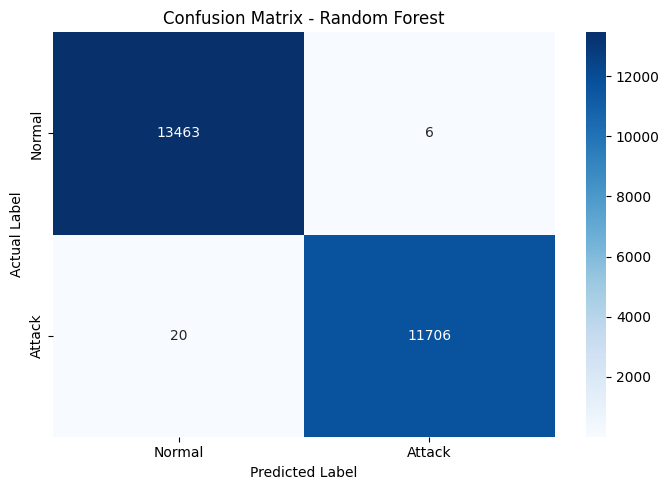

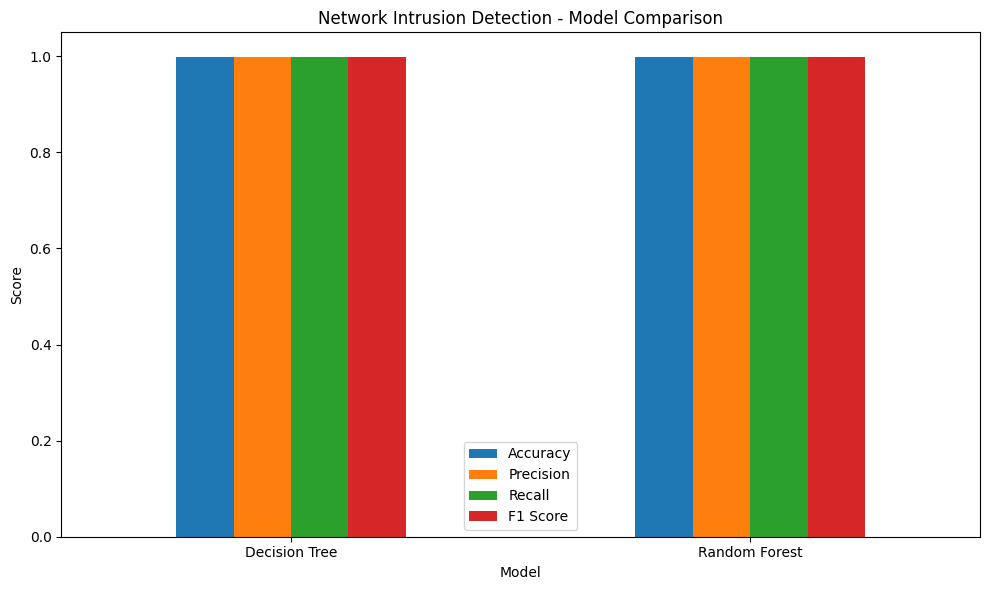

Graphs generated successfully!


In [19]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

best_model_name = results_df.loc[results_df["F1 Score"].idxmax(), "Model"]
best_model = trained_models[best_model_name]
y_pred = best_model.predict(X_test)

print("Best Model:", best_model_name)
print(classification_report(y_test, y_pred, target_names=["Normal", "Attack"]))

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(7, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Normal", "Attack"],
            yticklabels=["Normal", "Attack"])
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")
plt.title("Confusion Matrix - " + best_model_name)
plt.tight_layout()
plt.savefig("confusion_matrix.png")
plt.show()

results_df.set_index("Model")[["Accuracy", "Precision", "Recall", "F1 Score"]].plot(
    kind="bar", figsize=(10, 6)
)
plt.title("Network Intrusion Detection - Model Comparison")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig("model_comparison.png")
plt.show()

print("Graphs generated successfully!")

In [20]:
import joblib

joblib.dump(best_model, "intrusion_detection_model.pkl")
joblib.dump(list(X_train.columns), "feature_columns.pkl")

print("MODEL SAVED SUCCESSFULLY!")
print("Best model:", best_model_name)
print("Files saved:")
print("1. intrusion_detection_model.pkl")
print("2. feature_columns.pkl")

MODEL SAVED SUCCESSFULLY!
Best model: Random Forest
Files saved:
1. intrusion_detection_model.pkl
2. feature_columns.pkl


In [21]:
from google.colab import files

files.download("confusion_matrix.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [22]:
files.download("model_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>